# Build My Vulnerability Library

Create a persistent, updatable NVD cache on disk. `CacheBuilder` wraps
`VulnPipeline` with NVD feed-URL knowledge so you can build a library in
one line.

| Mode | Constructor |
|------|------------|
| All years (2002–now) | `CacheBuilder()` |
| Specific years | `CacheBuilder(years=[2024, 2025])` |
| Exclude years | `CacheBuilder(exclude_years=[2002])` |
| Modified feed only | `CacheBuilder(modified_only=True)` |
| Recent feed only | `CacheBuilder(recent_only=True)` |
| Years + Modified | `CacheBuilder(years=[2024], include_modified=True)` |

In [1]:
from vulnflow.helpers import CacheBuilder

# ensure() builds only if the file is missing or stale
ds = CacheBuilder(years=[2024, 2025]).ensure(
    "../data/library.parquet",
    max_age="7d",
)

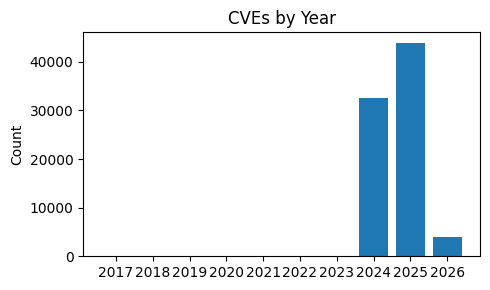

In [2]:
import matplotlib.pyplot as plt

yearly = ds.count_by("year")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(yearly["year"].astype(str), yearly["count"])
ax.set_title("CVEs by Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## Incremental Update

Pull the Modified feed as a delta, merge it with the base library,
and save the combined result. `from_parquet([base, delta])` performs
upsert by CVE ID — later files win on duplicates.

In [4]:
from pathlib import Path

from vulnflow import VulnDataset

# 1. Build delta from Modified feed
delta = CacheBuilder(modified_only=True).build()
delta.to_parquet("../data/delta.parquet")
print(f"Delta: {len(delta):,} records")

# 2. Merge base + delta (upsert by cve_id)
merged = VulnDataset.from_parquet(["../data/library.parquet", "../data/delta.parquet"])
print(f"Merged: {len(merged):,} records")

# 3. Save merged library
merged.to_parquet("../data/library.parquet")

# Clean up delta
Path("../data/delta.parquet").unlink(missing_ok=True)

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

Delta: 2,241 records
Merged: 83,136 records


## Round-Trip Verification

Reload from disk and verify no records were lost.

In [5]:
reloaded = VulnDataset.from_parquet("../data/library.parquet")

assert len(reloaded) == len(merged), f"Count mismatch: {len(reloaded)} vs {len(merged)}"
print(f"Round-trip OK: {len(reloaded):,} records, {len(reloaded.columns)} columns")

Round-trip OK: 83,136 records, 54 columns


## Provenance

Every dataset tracks which extractors and transforms have been applied.

In [7]:
prov = reloaded.provenance

print(f"Extractors : {prov['extractors']}")
print(f"Transforms : {prov['transforms']}")
print(f"Date range : {prov.get('date_min', '?')} .. {prov.get('date_max', '?')}")
print(f"Records    : {prov['record_count']:,}")
print(f"Version    : {prov['vulnflow_version']}")

Extractors : ["ParquetExtractor(['../data/library.parquet', '../data/delta.parquet'])", 'NVDExtractor(nvdcve-2.0-Modified.json.gz)', 'ParquetExtractor(library.parquet)']
Transforms : []
Date range : 2017-03-02T06:59:00.480000 .. 2026-02-15T14:16:07.763000
Records    : 83,136
Version    : 0.1.0
